3. سوالات تکلیف

3-2 ﺑﺨﺶ ﺩﻭﻡ: ﻛﺎﻧﻮﻟﻮﺷﻦ یک ﺑﻌﺪی ﺑﺮﺍی ﺩﺍﺩﻩ ﻫﺎی ﺳﺮی ﺯﻣﺎنی

ﺩﺭ ﺍﻳﻦ ﺑﺨﺶ ﺍﺯ ﺩﺍﺩﻩ ﻱ ﺳﺎﺧﺘﮕﻲ ﺳﻴﻨﻮﺳﻲ/ﻛﺴﻴﻨﻮﺳﻲ ﻣﻌﺮﻓﻲ ﺷﺪﻩ ﺩﺭ ﺑﺨﺶ ۲ ﺍﺳﺘﻔﺎﺩﻩ ﻣﻲ ﻛﻨﻴﺪ. یک ﻣﺪﻝ Conv1D  ﻣﺘﺸﻜﻞ ﺍﺯ یک ﻳﺎ ﺩﻭ ﻻﻳﻪ ﻛﺎﻧﻮﻟﻮﺷﻦ یک ﺑﻌﺪﻱ، ﭘﻮﻟﻴﻨﮓ ﻭ ﻻﻳﻪ ﻛﺎﻣﻼ ﻣﺘﺼﻞ ﻃﺮﺍﺣﻲ کنید.

3-2-1 ﺍﻧﺪﺍﺯﻩ ﻛﺮﻧﻞ ﺭﺍ ﺩﺭ ﻻﻳﻪ ﺍﻭﻝ ﺭﻭی ﻣﻘﺎﺩﻳﺮ ۳، ۵، ۷، ۱۱ ﺗﻐﻴﻴﺮ ﺩﻫﻴﺪ( padding=’same’ ،stride=1، ﺗﻌﺪﺍﺩ ﻓﻴﻠﺘﺮﻫﺎ=۸). دقت ﺭﻭﻱ ﺩﺍﺩﻩ ﺁﺯﻣﻮﻥ ﺭﺍ ﺑﺮﺍﻱ ﻫﺮ ﺣﺎﻟﺖ ﺛﺒﺖ ﻛﻨﻴﺪ.

الف) کدام ﺍﻧﺪﺍﺯﻩ ﻛﺮﻧﻞ ﺑﻬﺘﺮﻳﻦ ﻋﻤﻠﻜﺮﺩ ﺭﺍ ﺩﺍﺭﺩ؟ ﺑﺎ ﺗﻮﺟﻪ ﺑﻪ ﻃﻮﻝ ﺳﻴﮕﻨﺎﻝ (100) ﻭ ﻓﺮﻛﺎﻧﺲ ﺗﻐﻴﻴﺮﺍﺕ ﺳﻴﻨﻮﺳﻲ/ﻛﺴﻴﻨﻮﺳﻲ، ﺍﻳﻦ ﻧﺘﻴﺠﻪ ﺭﺍ ﺗﻮﺟﻴﻪ ﻛﻨﻴﺪ. 

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime
import os
from pathlib import Path
import sys
import time

sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_moons_data, get_mnist_data, generate_sine_cosine_data, generate_hard_sine_cosine_data
from plotting import plot_signals
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

In [11]:
num_samples = 1000
signal_len = 100
noise_std = 0.3

X, y = generate_sine_cosine_data(num_samples, signal_len, noise_std)
print(f"Dataset shape: X={X.shape}, y={y.shape}")
print(f"Class distribution: class0={(y==0).sum()}, class1={(y==1).sum()}")

# Train/test split (80/20)
split = int(0.8 * num_samples)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Convert to PyTorch tensors and add channel dimension (for Conv1D: (batch, channels, length))
X_train = torch.tensor(X_train).unsqueeze(1)  # shape: (N, 1, 100)
y_train = torch.tensor(y_train)
X_test = torch.tensor(X_test).unsqueeze(1)
y_test = torch.tensor(y_test)

batch_size = 64
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


Dataset shape: X=(1000, 100), y=(1000,)
Class distribution: class0=500, class1=500


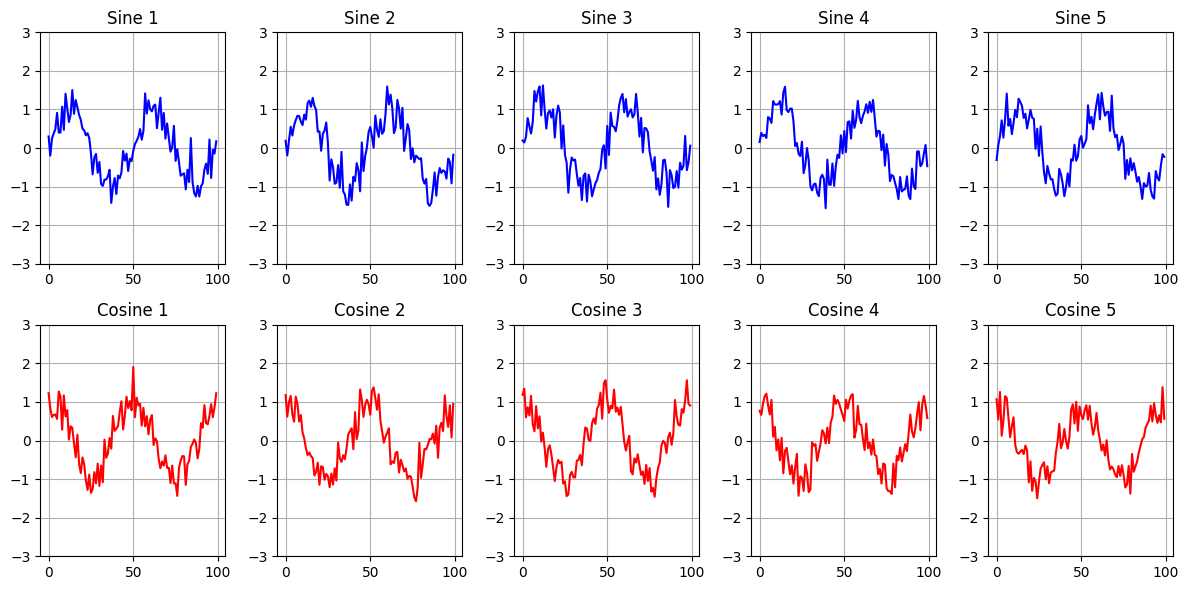

In [12]:
plot_signals(X,y)

In [43]:
num_samples = 1000
signal_len = 100
noise_std = 0.5

X, y = generate_hard_sine_cosine_data(num_samples, signal_len, (1, 3), (0, 0.33*np.pi), noise_std)
print(f"Dataset shape: X={X.shape}, y={y.shape}")
print(f"Class distribution: class0={(y==0).sum()}, class1={(y==1).sum()}")

# Train/test split (80/20)
split = int(0.8 * num_samples)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Convert to PyTorch tensors and add channel dimension (for Conv1D: (batch, channels, length))
X_train = torch.tensor(X_train).unsqueeze(1)  # shape: (N, 1, 100)
y_train = torch.tensor(y_train)
X_test = torch.tensor(X_test).unsqueeze(1)
y_test = torch.tensor(y_test)

batch_size = 64
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


Dataset shape: X=(1000, 100), y=(1000,)
Class distribution: class0=500, class1=500


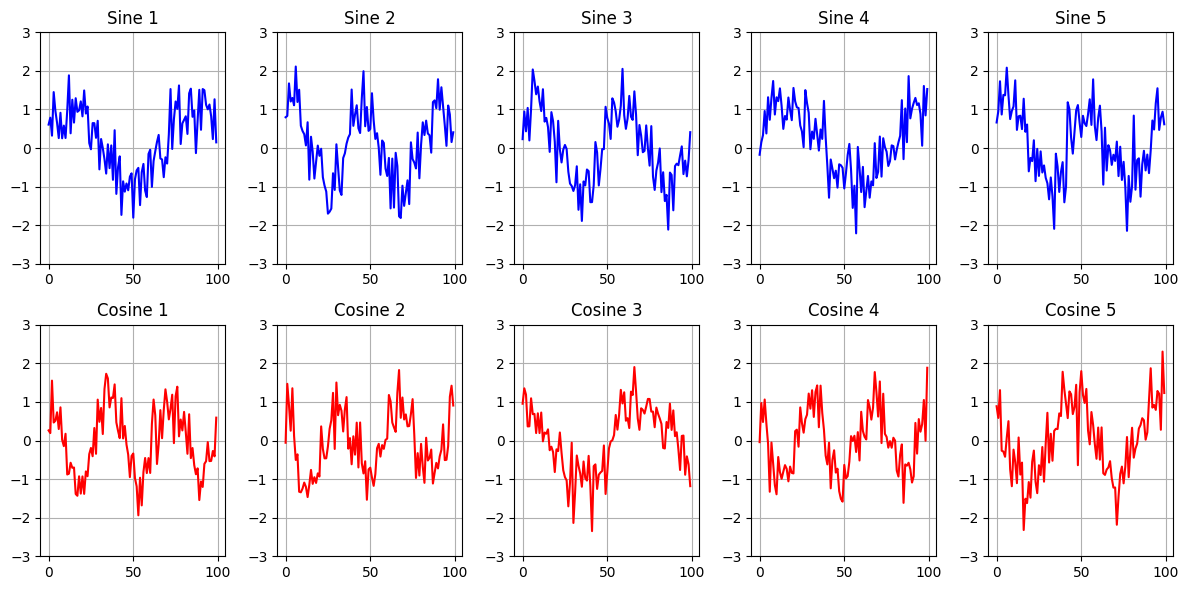

In [44]:
plot_signals(X,y)

In [45]:
class Conv1DClassifier(nn.Module):
    def __init__(self, kernel_size=3, stride=1, padding='same', num_filters=8, num_layers=2):
        super(Conv1DClassifier, self).__init__()
        layers = []
        in_channels = 1
        out_channels = num_filters
        for i in range(num_layers):
            layers.append(nn.Conv1d(in_channels, out_channels, kernel_size, stride, padding=padding))
            layers.append(nn.ReLU())
            layers.append(nn.MaxPool1d(kernel_size=2, stride=2))
            in_channels = out_channels
            out_channels = out_channels * 2 if i == 0 else out_channels  # double filters after first layer? Keep simple
        # Adjust: after two layers, we'll compute flattened size dynamically
        self.features = nn.Sequential(*layers)
        self._initialize_fc(signal_len)

    def _initialize_fc(self, input_len):
        with torch.no_grad():
            dummy = torch.zeros(1, 1, input_len)
            out = self.features(dummy)
            self.flatten_size = out.view(1, -1).size(1)
        self.fc = nn.Linear(self.flatten_size, 2)

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [46]:
def compute_1d_output_length(L_in, kernel, stride, padding):
    if padding == 'same':
        return L_in
    elif padding == 'valid':
        return (L_in - kernel) // stride + 1
    else:  # integer padding
        return (L_in + 2 * padding - kernel) // stride + 1


In [47]:
def train_model(model, train_loader, test_loader, epochs=20, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model.to(device)
    train_accs = []
    test_accs = []
    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        correct_train = 0
        total_train = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            _, pred = torch.max(outputs, 1)
            total_train += y_batch.size(0)
            correct_train += (pred == y_batch).sum().item()
        train_acc = 100 * correct_train / total_train
        train_accs.append(train_acc)

        # Test
        model.eval()
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for X_batch, y_batch in test_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                _, pred = torch.max(outputs, 1)
                total_test += y_batch.size(0)
                correct_test += (pred == y_batch).sum().item()
        test_acc = 100 * correct_test / total_test
        test_accs.append(test_acc)
        if (epoch+1) % 5 == 0:
            print(f"Epoch {epoch+1}/{epochs} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")
    elapsed = time.time() - start_time
    return train_accs, test_accs, elapsed


In [51]:
kernel_sizes = [3, 5, 7, 11]
results_kernel = []

for ks in kernel_sizes:
    print(f"\n===== Experiment: kernel size = {ks} =====")
    model = Conv1DClassifier(kernel_size=ks, stride=1, padding='same', num_filters=8, num_layers=2)
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Number of parameters: {num_params:,}")
    
    train_accs, test_accs, train_time = train_model(model, train_loader, test_loader, epochs=30, lr=0.001)
    final_test_acc = test_accs[-1]
    results_kernel.append({
        'kernel_size': ks,
        'params': num_params,
        'test_acc': final_test_acc,
        'train_time': train_time,
        'train_hist': train_accs,
        'test_hist': test_accs
    })
    print(f"Final test accuracy: {final_test_acc:.2f}%")



===== Experiment: kernel size = 3 =====
Number of parameters: 1,234
Epoch 5/30 | Train Acc: 91.25% | Test Acc: 93.00%
Epoch 10/30 | Train Acc: 97.62% | Test Acc: 96.00%
Epoch 15/30 | Train Acc: 98.38% | Test Acc: 97.50%
Epoch 20/30 | Train Acc: 98.38% | Test Acc: 98.00%
Epoch 25/30 | Train Acc: 99.12% | Test Acc: 98.00%
Epoch 30/30 | Train Acc: 99.12% | Test Acc: 98.50%
Final test accuracy: 98.50%

===== Experiment: kernel size = 5 =====
Number of parameters: 1,506
Epoch 5/30 | Train Acc: 93.75% | Test Acc: 96.50%
Epoch 10/30 | Train Acc: 98.00% | Test Acc: 97.00%
Epoch 15/30 | Train Acc: 98.75% | Test Acc: 98.00%
Epoch 20/30 | Train Acc: 99.00% | Test Acc: 97.50%
Epoch 25/30 | Train Acc: 98.62% | Test Acc: 98.00%
Epoch 30/30 | Train Acc: 98.88% | Test Acc: 98.00%
Final test accuracy: 98.00%

===== Experiment: kernel size = 7 =====
Number of parameters: 1,778
Epoch 5/30 | Train Acc: 94.25% | Test Acc: 95.50%
Epoch 10/30 | Train Acc: 97.50% | Test Acc: 96.00%
Epoch 15/30 | Train Acc: 9

In [52]:

# Display kernel results
df_kernel = pd.DataFrame([(r['kernel_size'], r['params'], r['test_acc'], r['train_time']) for r in results_kernel],
                         columns=['Kernel Size', '#Params', 'Test Acc (%)', 'Training Time (s)'])
print("\n===== Kernel Size Results =====")
print(df_kernel.to_string(index=False))
df_kernel.to_csv('kernel_size_1d_results.csv', index=False)



===== Kernel Size Results =====
 Kernel Size  #Params  Test Acc (%)  Training Time (s)
           3     1234          98.5           0.967431
           5     1506          98.0           0.971632
           7     1778          97.5           0.945263
          11     2322          97.0           0.974136


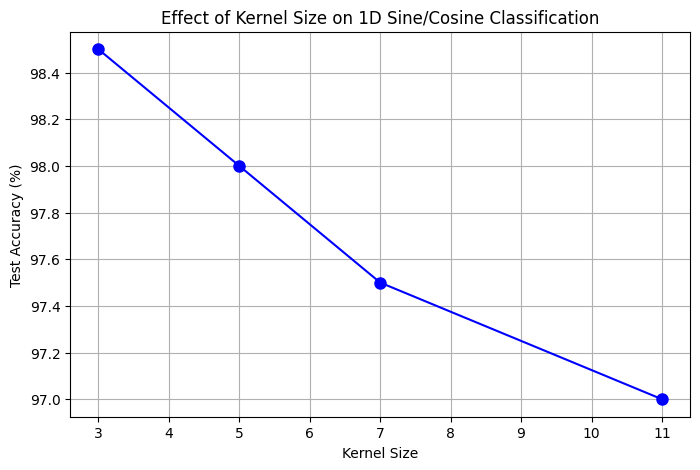

In [53]:

# Plot test accuracy vs kernel size
plt.figure(figsize=(8, 5))
plt.plot([r['kernel_size'] for r in results_kernel], [r['test_acc'] for r in results_kernel], 'bo-', markersize=8)
plt.xlabel('Kernel Size')
plt.ylabel('Test Accuracy (%)')
plt.title('Effect of Kernel Size on 1D Sine/Cosine Classification')
plt.grid(True)
plt.savefig('kernel_size_1d_accuracy.png', dpi=150)
plt.show()


ب) ﺍﮔﺮ ﺍﺯ ﻛﺮﻧﻞ ﺧﻴﻠﻲ ﺑﺰﺭﮒ (مثلا 51) ﺍﺳﺘﻔﺎﺩﻩ ﺷﻮﺩ، ﭼﻪ ﺍﺗﻔﺎﻗﻲ ﻣﻲ ﺍﻓﺘﺪ؟ (ﻣﻲ ﺗﻮﺍﻧﻴﺪ ﺁﺯﻣﺎﻳﺶ ﻛﻨﻴﺪ ﻳﺎ ﺍﺳﺘﺪﻻﻝ ﺗﺌﻮﺭﻱ ﺑﻴﺎﻭﺭﻳﺪ).

In [68]:
# Test large kernel = 51 (optional, uncomment to run)
print("\n===== Testing with extremely large kernel (51) =====")
model_large = Conv1DClassifier(kernel_size=51, stride=1, padding='same', num_filters=8, num_layers=2)
train_accs_large, test_accs_large, time_large = train_model(model_large, train_loader, test_loader, epochs=20, lr=0.001)
print(f"Large kernel (51) final test accuracy: {test_accs_large[-1]:.2f}%")



===== Testing with extremely large kernel (51) =====
Epoch 5/20 | Train Acc: 98.25% | Test Acc: 96.50%
Epoch 10/20 | Train Acc: 99.12% | Test Acc: 98.00%
Epoch 15/20 | Train Acc: 99.25% | Test Acc: 97.00%
Epoch 20/20 | Train Acc: 99.75% | Test Acc: 96.50%
Large kernel (51) final test accuracy: 96.50%


3-2-2 تاثیر ﭘﺪﻳﻨﮓ ﻭ ﺍﺳﺘﺮﺍﻳﺪ ﺭﺍ ﺭﻭی ﺩﺍﺩﻩ یک ﺑﻌﺪی ﻣﺸﺎﺑﻪ ﺑﺨﺶ ﻗﺒﻞ ﺑﺮﺭﺳﻲ ﻛﻨﻴﺪ. ﺁﻳﺎ ﻧﺘﺎﻳﺞ ﻣﺸﺎﺑﻪ ﺣﺎﻟﺖ ﺩﻭ ﺑﻌﺪﻱ ﺍﺳﺖ؟ ﺟﺪﻭﻝ ﻣﻘﺎﻳﺴﻪ ﺩﻗﺖ ﻭ ﺍﺑﻌﺎﺩ ﺧﺮﻭﺟﻲ ﺭﺍ ﺍﺭﺍﺋﻪ ﺩﻫﻴﺪ. 

In [72]:
import math
def get_same_padding(L_in, kernel, stride):
    """Return integer padding to achieve 'same' output length (ceil(L_in/stride))."""
    L_out = math.ceil(L_in / stride)
    # Solve: L_out = floor((L_in + 2p - kernel) / stride) + 1
    # => (L_out - 1) * stride = floor((L_in + 2p - kernel) / stride) * stride
    # Approx: (L_out - 1)*stride <= L_in + 2p - kernel < (L_out)*stride
    # => p = ceil(((L_out - 1)*stride + kernel - L_in) / 2)
    p = ((L_out - 1) * stride + kernel - L_in + 1) // 2
    # Ensure non-negative
    return max(0, p)


In [73]:
print("\n===== 3-2-2: Effect of Padding and Stride =====")
# Configurations: (stride, padding)
configs = [
    {'stride': 1, 'padding': 'same', 'desc': 'stride=1, padding=same'},
    {'stride': 1, 'padding': 'valid', 'desc': 'stride=1, padding=valid'},
    {'stride': 2, 'padding': 'auto_same', 'desc': 'stride=2, padding=auto_same (computed)'},
    {'stride': 2, 'padding': 1, 'desc': 'stride=2, padding=1 (fixed half-length)'}
]



===== 3-2-2: Effect of Padding and Stride =====


In [74]:
class Conv1DFlexible(nn.Module):
    def __init__(self, kernel_size=3, stride=1, padding='same', num_filters=8, num_layers=2, input_len=100):
        super(Conv1DFlexible, self).__init__()
        layers = []
        in_channels = 1
        out_channels = num_filters
        for i in range(num_layers):
            layers.append(nn.Conv1d(in_channels, out_channels, kernel_size, stride, padding=padding))
            layers.append(nn.ReLU())
            layers.append(nn.MaxPool1d(2, 2))
            in_channels = out_channels
            out_channels = out_channels * 2 if i == 0 else out_channels
        self.features = nn.Sequential(*layers)
        # Compute flattened size
        with torch.no_grad():
            dummy = torch.zeros(1, 1, input_len)
            out = self.features(dummy)
            self.flatten_size = out.view(1, -1).size(1)
        self.fc = nn.Linear(self.flatten_size, 2)
    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


In [75]:

results_padding_stride = []
for cfg in configs:
    print(f"\n--- {cfg['desc']} ---")
    pad = cfg['padding']
    stride = cfg['stride']
    kernel = 3
    L_in = 100
    
    # Convert padding to appropriate value for Conv1d
    if pad == 'same' and stride == 1:
        conv_pad = 'same'
        out_len_conv1 = L_in
    elif pad == 'valid':
        conv_pad = 0
        out_len_conv1 = (L_in - kernel) // stride + 1
    elif pad == 'auto_same':
        conv_pad = get_same_padding(L_in, kernel, stride)
        out_len_conv1 = math.ceil(L_in / stride)  # same behavior
        print(f"Computed padding = {conv_pad} gives output length {out_len_conv1}")
    else:  # integer padding
        conv_pad = int(pad)
        out_len_conv1 = (L_in + 2*conv_pad - kernel) // stride + 1
    
    # Build model with computed padding
    try:
        model = Conv1DFlexible(kernel_size=kernel, stride=stride, padding=conv_pad,
                               num_filters=8, num_layers=2, input_len=L_in)
    except Exception as e:
        print(f"Error building model: {e}. Skipping.")
        continue
    
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Output length after conv1: {out_len_conv1}")
    print(f"Number of parameters: {num_params}")
    
    # Train
    train_accs, test_accs, train_time = train_model(model, train_loader, test_loader, epochs=20, lr=0.001)
    final_acc = test_accs[-1]
    results_padding_stride.append({
        'config': cfg['desc'],
        'stride': stride,
        'padding': str(conv_pad),
        'out_len_conv1': out_len_conv1,
        'num_params': num_params,
        'test_acc': final_acc,
        'train_time': train_time
    })


--- stride=1, padding=same ---
Output length after conv1: 100
Number of parameters: 1234
Epoch 5/20 | Train Acc: 92.00% | Test Acc: 94.50%
Epoch 10/20 | Train Acc: 97.25% | Test Acc: 96.50%
Epoch 15/20 | Train Acc: 98.25% | Test Acc: 98.00%
Epoch 20/20 | Train Acc: 98.50% | Test Acc: 98.50%

--- stride=1, padding=valid ---
Output length after conv1: 98
Number of parameters: 1170
Epoch 5/20 | Train Acc: 88.12% | Test Acc: 90.50%
Epoch 10/20 | Train Acc: 97.88% | Test Acc: 98.00%
Epoch 15/20 | Train Acc: 98.38% | Test Acc: 98.00%
Epoch 20/20 | Train Acc: 98.62% | Test Acc: 98.00%

--- stride=2, padding=auto_same (computed) ---
Computed padding = 1 gives output length 50
Output length after conv1: 50
Number of parameters: 626
Epoch 5/20 | Train Acc: 86.12% | Test Acc: 88.00%
Epoch 10/20 | Train Acc: 94.12% | Test Acc: 93.00%
Epoch 15/20 | Train Acc: 96.38% | Test Acc: 93.50%
Epoch 20/20 | Train Acc: 97.38% | Test Acc: 92.00%

--- stride=2, padding=1 (fixed half-length) ---
Output length 

In [76]:
df_ps = pd.DataFrame(results_padding_stride)
print("\n===== Padding & Stride Results =====")
print(df_ps[['config', 'out_len_conv1', 'num_params', 'test_acc', 'train_time']].to_string(index=False))
df_ps.to_csv('padding_stride_1d_results.csv', index=False)


===== Padding & Stride Results =====
                                 config  out_len_conv1  num_params  test_acc  train_time
                 stride=1, padding=same            100        1234      98.5    0.669721
                stride=1, padding=valid             98        1170      98.0    0.626067
 stride=2, padding=auto_same (computed)             50         626      92.0    0.617056
stride=2, padding=1 (fixed half-length)             50         626      95.5    0.617242


3-2-3 ﺣﺪﺍﻗﻞ یک ﻧﻘﺸﻪ ﻭﻳﮋﮔﻲ ﺍﺯ ﻻﻳﻪ ﺍﻭﻝ ﻛﺎﻧﻮﻟﻮﺷﻦ (ﺑﺮﺍﻱ یک ﻧﻤﻮﻧﻪ ﺍﺯ ﺩﺍﺩﻩ ﺁﺯﻣﻮﻥ) ﺭﺍ ﺭﺳﻢ ﻛﻨﻴﺪ. ﺁﻳﺎ ﻣﻲ ﺗﻮﺍﻧﻴﺪ ﺍﺭﺗﺒﺎﻃﻲ ﺑﻴﻦ ﺍﻟﮕﻮﻱ ﺳﻴﮕﻨﺎﻝ ﻭﺭﻭﺩﻱ ﻭ ﻧﻘﺸﻪ ﻭﻳﮋﮔﻲ ﺧﺮﻭﺟﻲ ﭘﻴﺪﺍ ﻛﻨﻴﺪ؟ ﺑﺮﺍﻱ ﻣﺜﺎﻝ، ﻛﺮﻧﻞ ﻫﺎﻳﻲ ﻛﻪ ﺷﺒﻴﻪ ﻣﺸﺘﻖ ﮔﻴﺮ ﻳﺎ ﻫﻤﻮﺍﺭﺳﺎﺯ ﻫﺴﺘﻨﺪ ﺭﺍ ﺷﻨﺎﺳﺎﻳﻲ ﻛﻨﻴﺪ. 

In [81]:
best_kernel = max(results_kernel, key=lambda x: x['test_acc'])['kernel_size']
print(f"\nBest kernel size from earlier: {best_kernel}. Using it for feature map visualization.")
model_best = Conv1DClassifier(kernel_size=best_kernel, stride=1, padding='same', num_filters=8, num_layers=2)
# Train it quickly to get reasonable weights
train_model(model_best, train_loader, test_loader, epochs=50, lr=0.001)

# Get a test sample
model_best.eval()
sample, label = next(iter(test_loader))
sample = sample[0:1].to(device)  # shape (1,1,100)
label = label[0].item()

# Extract feature maps after first conv layer (before ReLU and pooling)
with torch.no_grad():
    # Access first conv layer
    conv1 = model_best.features[0]  # first Conv1d
    x = conv1(sample)               # output shape (1, 8, 100) because padding='same', stride=1
    feature_maps = x[0].cpu().numpy()  # (8, 100)



Best kernel size from earlier: 3. Using it for feature map visualization.
Epoch 5/50 | Train Acc: 91.00% | Test Acc: 93.50%
Epoch 10/50 | Train Acc: 98.00% | Test Acc: 97.50%
Epoch 15/50 | Train Acc: 98.38% | Test Acc: 97.50%
Epoch 20/50 | Train Acc: 98.88% | Test Acc: 98.00%
Epoch 25/50 | Train Acc: 98.75% | Test Acc: 97.50%
Epoch 30/50 | Train Acc: 98.88% | Test Acc: 98.00%
Epoch 35/50 | Train Acc: 98.88% | Test Acc: 97.50%
Epoch 40/50 | Train Acc: 99.00% | Test Acc: 97.50%
Epoch 45/50 | Train Acc: 99.00% | Test Acc: 97.50%
Epoch 50/50 | Train Acc: 99.25% | Test Acc: 97.50%


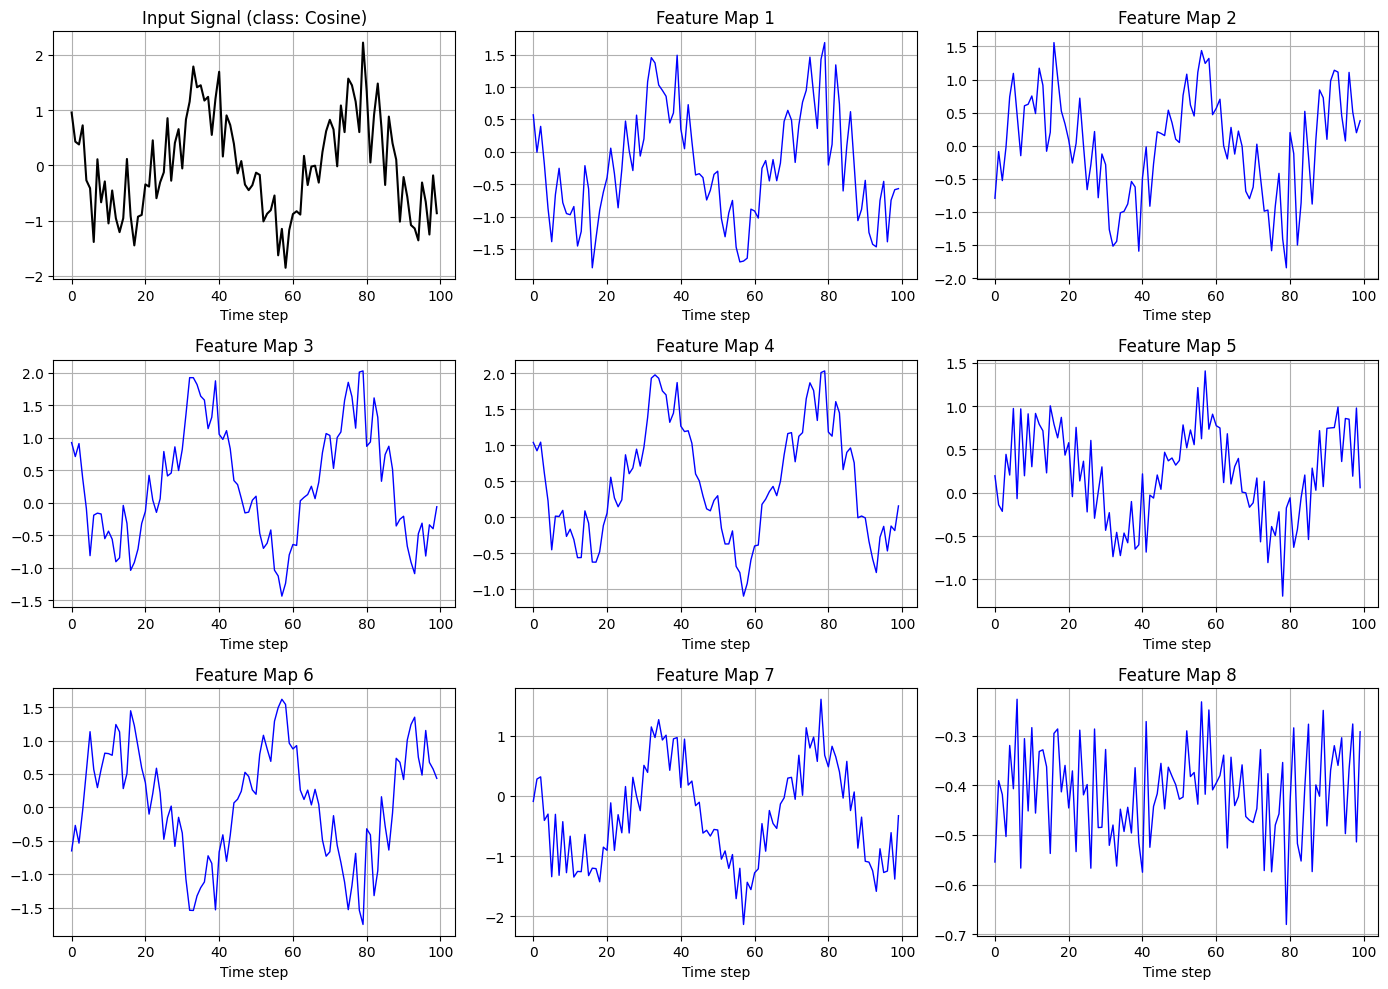

In [82]:
input_signal = sample[0,0].cpu().numpy()
plt.figure(figsize=(14, 10))
plt.subplot(3, 3, 1)
plt.plot(input_signal, 'k-', linewidth=1.5)
plt.title(f'Input Signal (class: {"Sine" if label==0 else "Cosine"})')
plt.xlabel('Time step')
plt.grid(True)

# Plot first 8 feature maps
for i in range(8):
    plt.subplot(3, 3, i+2)
    plt.plot(feature_maps[i], color='blue', linewidth=1)
    plt.title(f'Feature Map {i+1}')
    plt.xlabel('Time step')
    plt.grid(True)
plt.tight_layout()
plt.savefig('feature_maps_1d_example.png', dpi=150)
plt.show()


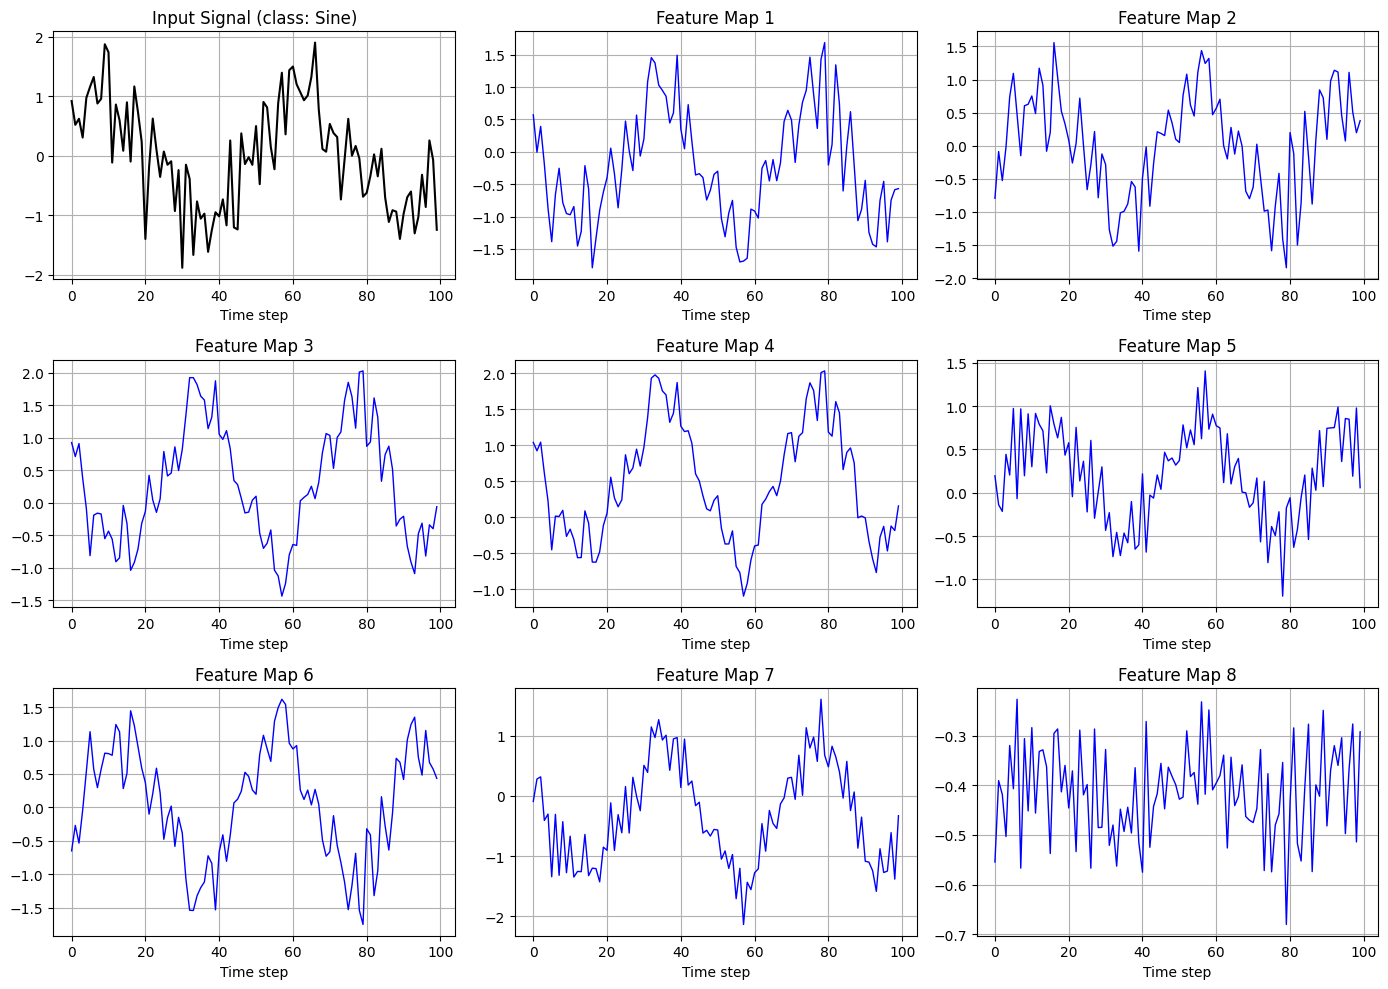

In [86]:
sample1, label1 = next(iter(test_loader))
sample1 = sample1[2:3].to(device)  # shape (1,1,100)
label1 = label1[2].item()

input_signal1 = sample1[0,0].cpu().numpy()
plt.figure(figsize=(14, 10))
plt.subplot(3, 3, 1)
plt.plot(input_signal1, 'k-', linewidth=1.5)
plt.title(f'Input Signal (class: {"Sine" if label1==0 else "Cosine"})')
plt.xlabel('Time step')
plt.grid(True)

# Plot first 8 feature maps
for i in range(8):
    plt.subplot(3, 3, i+2)
    plt.plot(feature_maps[i], color='blue', linewidth=1)
    plt.title(f'Feature Map {i+1}')
    plt.xlabel('Time step')
    plt.grid(True)
plt.tight_layout()
plt.savefig('feature_maps_1d_example.png', dpi=150)
plt.show()
